# 04 · Feature Engineering + LightGBM + Optuna (v3)

## Cambios respecto a v2

### Bug corregido
- Optuna: desacoplados `max_depth` y `num_leaves` — v2 generaba modelos triviales con `num_leaves=3`

### Feature engineering ampliado
- **Lag t-2**: valor de hace dos meses (además del t-1 ya existente)
- **Aceleración**: delta del delta — ¿el cambio se está acelerando o frenando?
- **Estadísticos de ventana**: media y desvío estándar de los últimos 3 meses por cliente
- **Nuevas combinaciones entre variables** (ver sección 2.5)

### Nuevas combinaciones motivadas por el análisis de errores
Los FN (churners perdidos en v2) tienen más antigüedad, más productos y mayor saldo.
Necesitamos features que capturen *deterioro progresivo en clientes estables*:
- Rentabilidad por producto (¿cae el valor individual aunque tenga muchos?)
- Actividad relativa (¿usa menos el homebanking respecto a sus transacciones totales?)
- Saldo relativo a la antigüedad (un saldo alto pero cayendo es señal fuerte)
- Comisiones sobre saldo (¿paga más por menos servicio?)

## Checkpoints
```
[CKPT_A] dataset_target_construido.parquet   ← input (notebook 03)
      ↓
[CKPT_B] dataset_fe_v3.parquet               ← post FE v3
      ↓
[CKPT_C] mejores_params_optuna_v3.json       ← params Optuna v3
      ↓
[CKPT_D] submission_v3_YYYYMMDD_HHMM.csv    ← output final
```

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 4 — Modelado v3  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna lightgbm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.5 MB/s eta 0:00:00


In [3]:
import gc
import warnings
import json
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP = RUTA_BASE / 'Competencia 1'
RUTA_COMP.mkdir(parents=True, exist_ok=True)

CKPT_A = RUTA_COMP / 'dataset_target_construido.parquet'
CKPT_B = RUTA_COMP / 'dataset_fe_v3.parquet'              # nuevo — no sobreescribe v2
CKPT_C = RUTA_COMP / 'mejores_params_optuna_v3.json'
ARCHIVO_SUBMISSION = RUTA_COMP / f'submission_v3_{datetime.now().strftime("%Y%m%d_%H%M")}.csv'
ARCHIVO_METRICAS   = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108

GANANCIA_TP =  1_072_500
COSTO_FP    =    -27_500
SEED        = 42

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_A, CKPT_B, CKPT_C]:
    print(f'  {ck.name}: {"✓ existe" if ck.exists() else "✗ pendiente"}')

Checkpoints:
  dataset_target_construido.parquet: ✓ existe
  dataset_fe_v3.parquet: ✗ pendiente
  mejores_params_optuna_v3.json: ✗ pendiente


## 1 · Funciones de ganancia

In [4]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia': tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def plot_ganancia_threshold(y_true, y_prob, titulo=''):
    df_t = ganancia_por_threshold(y_true, y_prob)
    opt  = df_t.loc[df_t['ganancia'].idxmax()].to_dict()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes[0]
    ax.plot(df_t['threshold'], df_t['ganancia'] / 1e9, color='#4C72B0', lw=2)
    ax.axvline(opt['threshold'], color='#C44E52', ls='--', lw=1.5,
               label=f"Óptimo: {opt['threshold']:.4f}")
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title(f'Ganancia vs Threshold {titulo}', fontweight='bold')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Ganancia ($B)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.legend(fontsize=9)
    ax = axes[1]
    ax.plot(df_t['threshold'], df_t['n_intervenidos'], color='#DD8452', lw=2)
    ax.axvline(opt['threshold'], color='#C44E52', ls='--', lw=1.5)
    ax.set_title(f'Clientes a intervenir vs Threshold {titulo}', fontweight='bold')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('N clientes')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    plt.show()
    print(f"  Threshold óptimo:   {opt['threshold']:.5f}")
    print(f"  Ganancia:           ${opt['ganancia']:>15,.0f}")
    print(f"  TP detectados:      {opt['tp']:,}")
    print(f"  FP (en vano):       {opt['fp']:,}")
    print(f"  Total intervenidos: {opt['n_intervenidos']:,}")
    return opt

print('✓ Funciones de ganancia listas.')

✓ Funciones de ganancia listas.


## 2 · Feature Engineering v3

Si `dataset_fe_v3.parquet` existe, lo cargamos y saltamos esta sección.

In [5]:
if CKPT_B.exists():
    print(f'✓ CKPT_B encontrado — cargando dataset_fe_v3.parquet...')
    df = pd.read_parquet(CKPT_B)
    print(f'  {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb(df):.1f} MB')
    FEATURE_COLS = [c for c in df.columns
                    if c not in {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}]
    print(f'  Features: {len(FEATURE_COLS)}')
    print('  → Saltá a la sección 3.')
else:
    print('✗ CKPT_B no encontrado — ejecutar FE a continuación.')

✗ CKPT_B no encontrado — ejecutar FE a continuación.


In [6]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():
    df = pd.read_parquet(CKPT_A)
    df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
    print(f'CKPT_A cargado: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

CKPT_A cargado: 983,061 × 156 — 411.6 MB


In [7]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # ── Interpolación (igual que v2) ──────────────────────────────────────────
    NO_INTERPOLAR = {
        COL_ID, COL_PERIODO, TARGET_RAW, TARGET,
        'active_quarter', 'cliente_vip', 'internet',
        'tcallcenter', 'thomebanking', 'tmobile_app',
    }
    NO_INTERPOLAR.update([c for c in df.columns
                          if c.startswith('c') and
                          df[c].dtype in ['uint8','uint16','uint32','int8','int16','int32']])
    NO_INTERPOLAR.update([c for c in df.columns
                          if c.startswith('Visa_') or c.startswith('Master_')])

    COLS_INTERPOLAR = [c for c in df.select_dtypes(include=['float32','float64']).columns
                       if c not in NO_INTERPOLAR]

    nulos_antes = df[COLS_INTERPOLAR].isna().sum().sum()
    df[COLS_INTERPOLAR] = (
        df.groupby(COL_ID)[COLS_INTERPOLAR]
        .transform(lambda s: s.interpolate(method='linear', limit=1, limit_direction='both'))
    )
    print(f'Interpolación: {nulos_antes - df[COLS_INTERPOLAR].isna().sum().sum():,} NaN rellenados')
    gc.collect()

Interpolación: 44,094 NaN rellenados


In [8]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # Variables base para FE temporal (lags, deltas, ventanas)
    COLS_FE = [
        'mrentabilidad', 'mrentabilidad_annual', 'mcomisiones',
        'mactivos_margen', 'mpasivos_margen',
        'mcuentas_saldo', 'mcuenta_corriente', 'mcaja_ahorro', 'mcaja_ahorro_dolares',
        'chomebanking_transacciones', 'cmobile_app_trx', 'ctrx_quarter',
        'cproductos', 'tcuentas',
        'ctarjeta_visa_transacciones', 'ctarjeta_master_transacciones',
        'mpayroll', 'ctransferencias_emitidas', 'ctransferencias_recibidas',
        'catm_trx', 'matm',
        'mprestamos_personales', 'mprestamos_hipotecarios',
        'cliente_antiguedad',
    ]
    COLS_FE = [c for c in COLS_FE if c in df.columns]
    print(f'Variables base para FE temporal: {len(COLS_FE)}')

    # ── 2.1 Lag t-1, Delta, Delta relativo ───────────────────────────────────
    print('Generando lag1, delta1, drel1...')
    for col in COLS_FE:
        lag1 = df.groupby(COL_ID)[col].shift(1).astype('float32')
        df[f'{col}_lag1']  = lag1
        df[f'{col}_delta1'] = (df[col] - lag1).astype('float32')
        df[f'{col}_drel1']  = (df[f'{col}_delta1'] / lag1.abs().replace(0, np.nan)).clip(-10, 10).astype('float32')
        del lag1
    gc.collect()
    print(f'  RAM: {mem_mb(df):.1f} MB | Columnas: {df.shape[1]}')

Variables base para FE temporal: 24
Generando lag1, delta1, drel1...
  RAM: 681.6 MB | Columnas: 228


In [9]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # ── 2.2 Lag t-2 y Aceleración ────────────────────────────────────────────
    # Aceleración = delta1 - delta_del_mes_anterior
    # Captura si el deterioro se ACELERA (señal fuerte de churn inminente)
    print('Generando lag2 y aceleración...')
    for col in COLS_FE:
        lag2   = df.groupby(COL_ID)[col].shift(2).astype('float32')
        delta2 = (df[f'{col}_lag1'] - lag2).astype('float32')   # delta del mes anterior
        df[f'{col}_lag2']   = lag2
        # aceleración: ¿el delta de hoy es mayor que el de ayer? → deterioro acelerándose
        df[f'{col}_acel']   = (df[f'{col}_delta1'] - delta2).astype('float32')
        del lag2, delta2
    gc.collect()
    print(f'  RAM: {mem_mb(df):.1f} MB | Columnas: {df.shape[1]}')

Generando lag2 y aceleración...
  RAM: 861.6 MB | Columnas: 276


In [10]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # ── 2.3 Media y desvío estándar — ventana de 3 meses ─────────────────────
    # Media: nivel promedio reciente (más estable que el valor puntual)
    # Desvío: volatilidad del cliente — alta volatilidad + caída = riesgo
    # Solo para variables de mayor señal (no todas para no explotar RAM)
    COLS_VENTANA = [
        'mrentabilidad', 'mcuentas_saldo', 'mcuenta_corriente',
        'mcomisiones', 'cproductos', 'chomebanking_transacciones',
        'ctrx_quarter', 'mactivos_margen',
    ]
    COLS_VENTANA = [c for c in COLS_VENTANA if c in df.columns]

    print(f'Generando media y std (ventana 3) para {len(COLS_VENTANA)} variables...')
    for col in COLS_VENTANA:
        grp = df.groupby(COL_ID)[col]
        df[f'{col}_media3'] = grp.transform(lambda s: s.rolling(3, min_periods=2).mean()).astype('float32')
        df[f'{col}_std3']   = grp.transform(lambda s: s.rolling(3, min_periods=2).std()).astype('float32')
        # Coeficiente de variación: std / |media| — normaliza la escala
        df[f'{col}_cv3']    = (
            df[f'{col}_std3'] / df[f'{col}_media3'].abs().replace(0, np.nan)
        ).clip(0, 10).astype('float32')
    gc.collect()
    print(f'  RAM: {mem_mb(df):.1f} MB | Columnas: {df.shape[1]}')

Generando media y std (ventana 3) para 8 variables...
  RAM: 951.6 MB | Columnas: 300


In [11]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # ── 2.4 Tendencia 3 meses (igual que v2) ─────────────────────────────────
    COLS_TEND = [
        'mrentabilidad', 'mcuentas_saldo', 'mcuenta_corriente',
        'mcaja_ahorro', 'mcomisiones', 'cproductos',
        'chomebanking_transacciones', 'ctrx_quarter'
    ]
    COLS_TEND = [c for c in COLS_TEND if c in df.columns]

    def slope_3(w):
        if np.isnan(w).any(): return np.nan
        return float(np.polyfit([0, 1, 2], w, 1)[0])

    print(f'Generando tendencias para {len(COLS_TEND)} variables...')
    for col in COLS_TEND:
        df[f'{col}_tend3'] = (
            df.groupby(COL_ID)[col]
            .transform(lambda s: s.rolling(3, min_periods=3).apply(slope_3, raw=True))
            .astype('float32')
        )
    gc.collect()
    print(f'  RAM: {mem_mb(df):.1f} MB | Columnas: {df.shape[1]}')

Generando tendencias para 8 variables...
  RAM: 981.6 MB | Columnas: 308


In [12]:
# ── Solo si CKPT_B no existe ──────────────────────────────────────────────────
if not CKPT_B.exists():

    # ── 2.5 Nuevas combinaciones entre variables ───────────────────────────────
    # Motivadas por el análisis de errores v2:
    # Los FN (churners perdidos) tienen más antigüedad, más productos y mayor saldo.
    # Necesitamos capturar deterioro relativo en clientes estables.

    def safe_div(a, b, clip=100):
        return (a / b.replace(0, np.nan)).clip(-clip, clip).astype('float32')

    # --- Rentabilidad por producto ---
    # Un cliente con muchos productos pero poca rentabilidad = señal de desenganche
    if 'mrentabilidad' in df.columns and 'cproductos' in df.columns:
        df['rentab_por_producto'] = safe_div(df['mrentabilidad'], df['cproductos'])
        # ¿Está cayendo esa rentabilidad por producto?
        df['rentab_por_prod_delta'] = (
            df.groupby(COL_ID)['rentab_por_producto']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Digitalización relativa ---
    # ¿El cliente usa cada vez menos los canales digitales respecto a sus transacciones?
    # Caída en digitalización = síntoma de desenganche temprano
    if 'chomebanking_transacciones' in df.columns and 'ctrx_quarter' in df.columns:
        df['ratio_digital'] = safe_div(
            df.get('chomebanking_transacciones', 0).fillna(0) +
            df.get('cmobile_app_trx', pd.Series(0, index=df.index)).fillna(0),
            df['ctrx_quarter']
        ).clip(0, 1)
        df['ratio_digital_delta'] = (
            df.groupby(COL_ID)['ratio_digital']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Comisiones sobre rentabilidad ---
    # Si las comisiones crecen pero la rentabilidad cae → cliente insatisfecho
    if 'mcomisiones' in df.columns and 'mrentabilidad' in df.columns:
        df['ratio_comis_rentab'] = safe_div(df['mcomisiones'], df['mrentabilidad'].abs())
        df['ratio_comis_rentab_delta'] = (
            df.groupby(COL_ID)['ratio_comis_rentab']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Saldo sobre antigüedad ---
    # Un cliente antiguo con saldo cayendo es mucho más alarmante
    # que un cliente nuevo con saldo cayendo
    if 'mcuentas_saldo' in df.columns and 'cliente_antiguedad' in df.columns:
        df['saldo_por_antig'] = safe_div(
            df['mcuentas_saldo'],
            df['cliente_antiguedad'].replace(0, np.nan)
        )

    # --- Payroll sobre saldo ---
    # ¿Qué porcentaje del payroll queda depositado? Baja = cliente está retirando todo
    if 'mpayroll' in df.columns and 'mcuentas_saldo' in df.columns:
        df['ratio_payroll_saldo'] = safe_div(df['mpayroll'], df['mcuentas_saldo'].abs())

    # --- Utilización de tarjeta Visa ---
    if 'mtarjeta_visa_consumo' in df.columns and 'Visa_mlimitecompra' in df.columns:
        df['visa_utilizacion'] = safe_div(
            df['mtarjeta_visa_consumo'], df['Visa_mlimitecompra'])
        df['visa_utilizacion_delta'] = (
            df.groupby(COL_ID)['visa_utilizacion']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Utilización de tarjeta Master ---
    if 'mtarjeta_master_consumo' in df.columns and 'Master_mlimitecompra' in df.columns:
        df['master_utilizacion'] = safe_div(
            df['mtarjeta_master_consumo'], df['Master_mlimitecompra'])
        df['master_utilizacion_delta'] = (
            df.groupby(COL_ID)['master_utilizacion']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Margen neto: activos - pasivos ---
    # ¿El cliente genera más de lo que cuesta para el banco?
    if 'mactivos_margen' in df.columns and 'mpasivos_margen' in df.columns:
        df['margen_neto'] = (df['mactivos_margen'] - df['mpasivos_margen'].abs()).astype('float32')
        df['margen_neto_delta'] = (
            df.groupby(COL_ID)['margen_neto']
            .transform(lambda s: s.diff())
            .astype('float32')
        )

    # --- Deuda total sobre payroll (endeudamiento relativo) ---
    cols_deuda = ['mprestamos_personales', 'mprestamos_hipotecarios', 'mprestamos_prendarios']
    cols_deuda_ok = [c for c in cols_deuda if c in df.columns]
    if cols_deuda_ok and 'mpayroll' in df.columns:
        deuda_total = sum(df[c].fillna(0) for c in cols_deuda_ok)
        df['ratio_deuda_payroll'] = safe_div(deuda_total, df['mpayroll'].abs())

    # ── 2.6 Flags ─────────────────────────────────────────────────────────────
    df['flag_primer_mes'] = (
        df.groupby(COL_ID)[COL_PERIODO].transform('min') == df[COL_PERIODO]
    ).astype('int8')

    if 'Visa_msaldototal' in df.columns:
        df['flag_tiene_visa']   = df['Visa_msaldototal'].notna().astype('int8')
    if 'Master_msaldototal' in df.columns:
        df['flag_tiene_master'] = df['Master_msaldototal'].notna().astype('int8')

    cols_prestamo = ['cprestamos_personales', 'cprestamos_hipotecarios', 'cprestamos_prendarios']
    cols_prestamo_ok = [c for c in cols_prestamo if c in df.columns]
    if cols_prestamo_ok:
        df['flag_tiene_prestamo'] = (
            sum(df[c].fillna(0) for c in cols_prestamo_ok) > 0
        ).astype('int8')

    gc.collect()
    print(f'FE v3 completo — {df.shape[1]} columnas — RAM: {mem_mb(df):.1f} MB')

FE v3 completo — 327 columnas — RAM: 1041.6 MB


In [ ]:
# ── Guardar CKPT_B ────────────────────────────────────────────────────────────
if not CKPT_B.exists():
    print(f'Guardando CKPT_B...')
    df.to_parquet(CKPT_B, index=False, engine='pyarrow')
    print(f'✓ {CKPT_B.name} ({CKPT_B.stat().st_size/1024**2:.1f} MB en disco)')

FEATURE_COLS = [c for c in df.columns if c not in {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}]
print(f'Features para el modelo: {len(FEATURE_COLS)}')

Guardando CKPT_B...
✓ dataset_fe_v3.parquet (433.6 MB en disco)
Features para el modelo: 323


## 3 · Splits walk-forward

In [ ]:
assert 'df' in dir(), 'df no está en memoria — corré desde la sección 2'

FEATURE_COLS = [c for c in df.columns if c not in {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}]

mask_entren = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_tot = df.loc[mask_entren, TARGET]
SCALE_POS_WEIGHT = float((y_tot == 0).sum() / (y_tot == 1).sum())
del y_tot; gc.collect()

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],        'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105],'test': 202106},
]

def get_split(meses_train, mes_test):
    mt = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[TARGET].notna()
    return (df.loc[mt, FEATURE_COLS], df.loc[mt, TARGET].astype(int),
            df.loc[me, FEATURE_COLS], df.loc[me, TARGET].astype(int))

print(f'scale_pos_weight: {SCALE_POS_WEIGHT:.1f} | Features: {len(FEATURE_COLS)} | RAM: {mem_mb(df):.1f} MB')
for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    print(f"{fold['nombre']}: train={len(ytr):,} (baja2={ytr.sum()}) | test={len(yte):,} (baja2={yte.sum()})")

AssertionError: df no está en memoria — corré desde la sección 2

## 4 · Baseline v3

In [ ]:
# Baseline con parámetros razonables (no los triviales de v2)
PARAMS_BASE = {
    'objective': 'binary', 'metric': 'binary_logloss',
    'boosting_type': 'gbdt', 'verbosity': -1, 'n_jobs': -1,
    'random_state': SEED,
    'num_leaves': 63,          # 2^6 - 1 — árbol mediano, razonable para este dataset
    'max_depth': 6,
    'learning_rate': 0.05,
    'n_estimators': 500,
    'min_child_samples': 50,
    'subsample': 0.8, 'subsample_freq': 1,
    'colsample_bytree': 0.8,
    'scale_pos_weight': SCALE_POS_WEIGHT,
}

print('Entrenando baseline v3 (fold_4)...')
Xtr, ytr, Xte, yte = get_split([202103, 202104, 202105], 202106)

modelo_base = lgb.LGBMClassifier(**PARAMS_BASE)
modelo_base.fit(
    Xtr, ytr,
    eval_set=[(Xte, yte)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
)
prob_base = modelo_base.predict_proba(Xte)[:, 1]
auc_base  = roc_auc_score(yte, prob_base)
print(f'AUC baseline v3: {auc_base:.4f}')

del Xtr, ytr; gc.collect()

Entrenando baseline v3 (fold_4)...
AUC baseline v3: 0.8613


162

=== BASELINE v3 — fold_4 ===


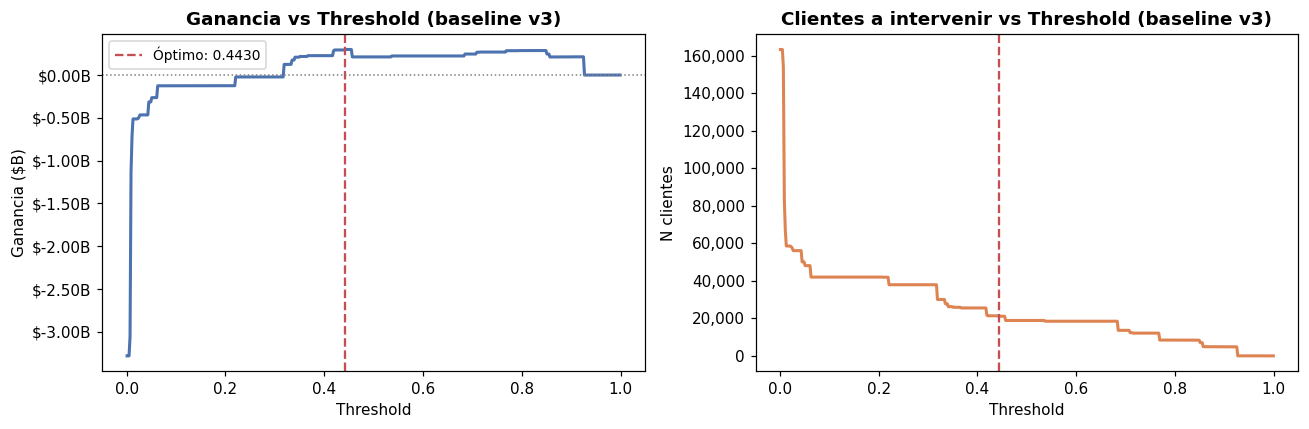

  Threshold óptimo:   0.44300
  Ganancia:           $    298,375,000
  TP detectados:      799.0
  FP (en vano):       20,311.0
  Total intervenidos: 21,110.0


6649

In [ ]:
print('=== BASELINE v3 — fold_4 ===')
opt_base = plot_ganancia_threshold(yte.values, prob_base, '(baseline v3)')
del Xte, yte; gc.collect()

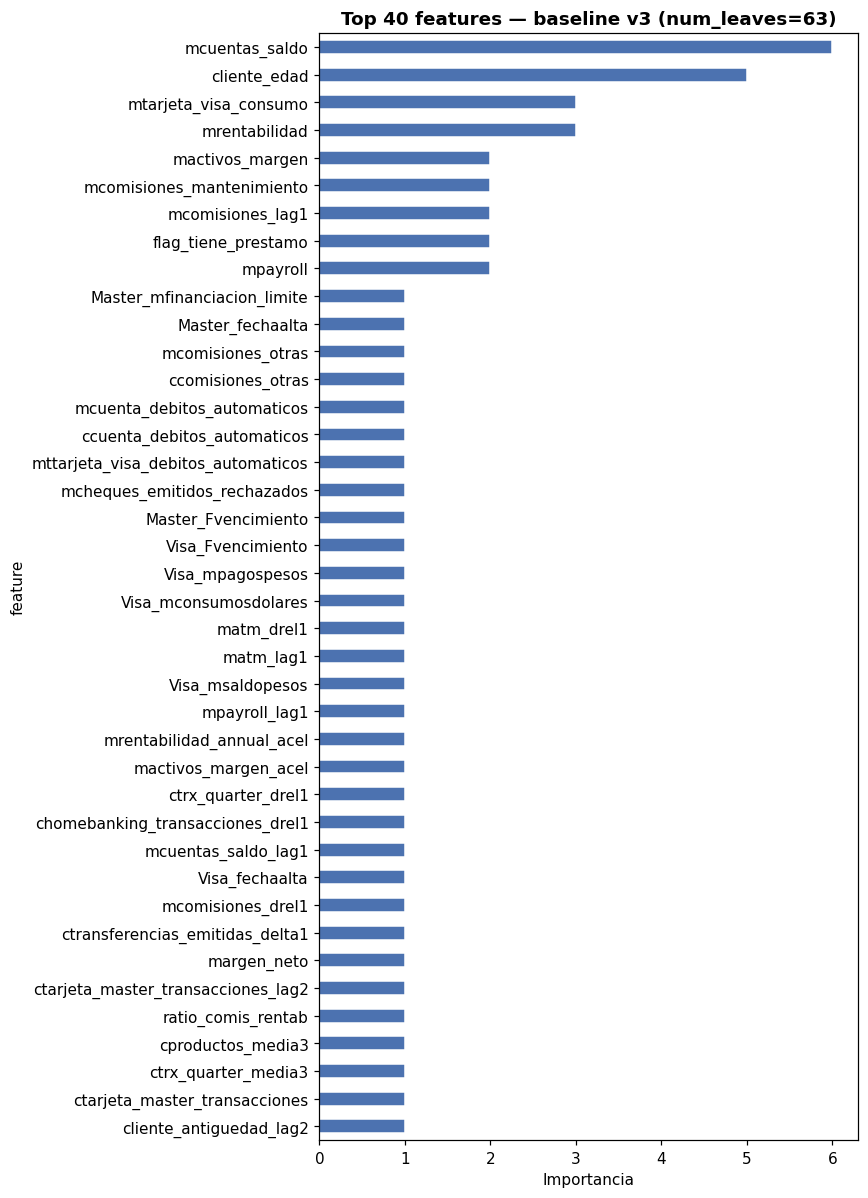

Top 20:
                           feature  importance
                    mcuentas_saldo           6
                      cliente_edad           5
             mtarjeta_visa_consumo           3
                     mrentabilidad           3
               flag_tiene_prestamo           2
                  mcomisiones_lag1           2
         mcomisiones_mantenimiento           2
                          mpayroll           2
                   mactivos_margen           2
                       margen_neto           1
                ratio_comis_rentab           1
ctarjeta_master_transacciones_lag2           1
           cliente_antiguedad_lag2           1
               ctrx_quarter_media3           1
                 cproductos_media3           1
     ctarjeta_master_transacciones           1
                     mpayroll_lag1           1
         mrentabilidad_annual_acel           1
              mactivos_margen_acel           1
                ctrx_quarter_drel1           1

Feat

In [ ]:
# Feature importance baseline v3
fi = pd.DataFrame({'feature': modelo_base.feature_name_,
                   'importance': modelo_base.feature_importances_}
                  ).sort_values('importance', ascending=False)

top_n = 40
fig, ax = plt.subplots(figsize=(8, 11))
fi.head(top_n).sort_values('importance').plot(
    kind='barh', x='feature', y='importance', ax=ax,
    color='#4C72B0', edgecolor='white', legend=False)
ax.set_title(f'Top {top_n} features — baseline v3 (num_leaves=63)', fontweight='bold')
ax.set_xlabel('Importancia')
plt.tight_layout()
plt.show()

cero_imp = fi[fi['importance'] == 0]
print(f'Top 20:\n{fi.head(20).to_string(index=False)}')
print(f'\nFeatures con importancia=0: {len(cero_imp)}')

# ¿Las nuevas combinaciones aparecen?
nuevas = ['rentab_por_producto', 'ratio_digital', 'ratio_comis_rentab',
          'saldo_por_antig', 'ratio_payroll_saldo', 'visa_utilizacion',
          'master_utilizacion', 'margen_neto', 'ratio_deuda_payroll']
nuevas_en_top50 = fi[fi['feature'].isin(nuevas)].head(50)
print(f'\nNuevas combinaciones en el ranking:')
print(nuevas_en_top50[['feature','importance']].to_string(index=False))

## 5 · Optuna v3 — búsqueda corregida

**Fix aplicado:** `max_depth` y `num_leaves` desacoplados.
No hay constraint entre ellos — LightGBM los maneja independientemente.
El árbol crece hoja por hoja hasta `num_leaves` o hasta que `max_depth` lo corte.

**Comparación con v2:**
- v2: `num_leaves` ∈ [2, 2^max_depth-1] → con max_depth=3 solo podía ser 2-7
- v3: `num_leaves` ∈ [16, 256] siempre → el modelo puede ser tan complejo como necesite

In [ ]:
if CKPT_C.exists():
    print(f'✓ CKPT_C encontrado — cargando params...')
    with open(CKPT_C) as f:
        params_guardados = json.load(f)
    PARAMS_OPT = {k: v for k, v in params_guardados.items()
                  if k not in {'ganancia_optuna_fold4', 'n_trials', 'fecha', 'auc_fold4'}}
    PARAMS_OPT.update({'objective': 'binary', 'metric': 'binary_logloss',
                       'boosting_type': 'gbdt', 'verbosity': -1,
                       'n_jobs': -1, 'random_state': SEED})
    print(f'  Ganancia Optuna (fold4): ${params_guardados["ganancia_optuna_fold4"]:,.0f}')
    print('  → Saltá a la sección 6.')
else:
    print('✗ CKPT_C no encontrado — ejecutar Optuna.')

✗ CKPT_C no encontrado — ejecutar Optuna.


In [ ]:
# ── Solo si CKPT_C no existe ──────────────────────────────────────────────────
if not CKPT_C.exists():

    Xtr_opt, ytr_opt, Xte_opt, yte_opt = get_split([202103, 202104, 202105], 202106)
    yte_opt_arr = yte_opt.values

    def objective_optuna(trial):
        params = {
            'objective': 'binary', 'metric': 'binary_logloss',
            'boosting_type': 'gbdt', 'verbosity': -1,
            'n_jobs': -1, 'random_state': SEED,
            # ── Desacoplados (fix v3) ──────────────────────────────────────────
            'num_leaves':  trial.suggest_int('num_leaves', 16, 256),
            'max_depth':   trial.suggest_int('max_depth', 4, 12),
            # ── Resto de hiperparámetros ───────────────────────────────────────
            'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'n_estimators':      trial.suggest_int('n_estimators', 100, 1000, step=50),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 300),
            'feature_fraction':  trial.suggest_float('feature_fraction', 0.4, 1.0),
            'bagging_fraction':  trial.suggest_float('bagging_fraction', 0.4, 1.0),
            'bagging_freq':      trial.suggest_int('bagging_freq', 1, 7),
            'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
            # scale_pos_weight: exploramos entre mitad y 1.5x del ratio natural
            'scale_pos_weight':  trial.suggest_float('scale_pos_weight',
                                                      SCALE_POS_WEIGHT / 4,
                                                      SCALE_POS_WEIGHT * 1.5),
        }
        model = lgb.LGBMClassifier(**params)
        model.fit(Xtr_opt, ytr_opt,
                  eval_set=[(Xte_opt, yte_opt)],
                  callbacks=[lgb.early_stopping(30, verbose=False), lgb.log_evaluation(-1)])
        prob = model.predict_proba(Xte_opt)[:, 1]
        del model; gc.collect()
        return threshold_optimo(yte_opt_arr, prob)['ganancia']

    # 50 trials — subir a 100 si el tiempo lo permite
    N_TRIALS = 50

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name='lgbm_churn_v3'
    )
    study.optimize(objective_optuna, n_trials=N_TRIALS, show_progress_bar=True)

    del Xtr_opt, ytr_opt, Xte_opt; gc.collect()

    print(f'\n✓ Optuna v3 completado — {N_TRIALS} trials')
    print(f'Mejor ganancia: ${study.best_value:,.0f}')
    print('Mejores parámetros:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    PARAMS_OPT = {
        'objective': 'binary', 'metric': 'binary_logloss',
        'boosting_type': 'gbdt', 'verbosity': -1,
        'n_jobs': -1, 'random_state': SEED,
        **study.best_params
    }

    # Guardamos CKPT_C
    auc_check = roc_auc_score(yte_opt_arr,
        lgb.LGBMClassifier(**PARAMS_OPT).fit(
            *get_split([202103,202104,202105], 202106)[:2],
            callbacks=[lgb.log_evaluation(-1)]
        ).predict_proba(get_split([202103,202104,202105], 202106)[2])[:, 1]
    )
    guardar = {**study.best_params,
               'ganancia_optuna_fold4': study.best_value,
               'auc_fold4': round(auc_check, 4),
               'n_trials': N_TRIALS,
               'fecha': datetime.now().isoformat()}
    with open(CKPT_C, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'✓ CKPT_C guardado: {CKPT_C.name}')

  0%|          | 0/50 [00:00<?, ?it/s]


✓ Optuna v3 completado — 50 trials
Mejor ganancia: $377,685,000
Mejores parámetros:
  num_leaves: 24
  max_depth: 5
  learning_rate: 0.025832729613126503
  n_estimators: 950
  min_child_samples: 168
  feature_fraction: 0.6386999057405924
  bagging_fraction: 0.4270280340719993
  bagging_freq: 4
  reg_alpha: 0.0014826385435596646
  reg_lambda: 0.5480606961681793
  scale_pos_weight: 223.3988606436954
✓ CKPT_C guardado: mejores_params_optuna_v3.json


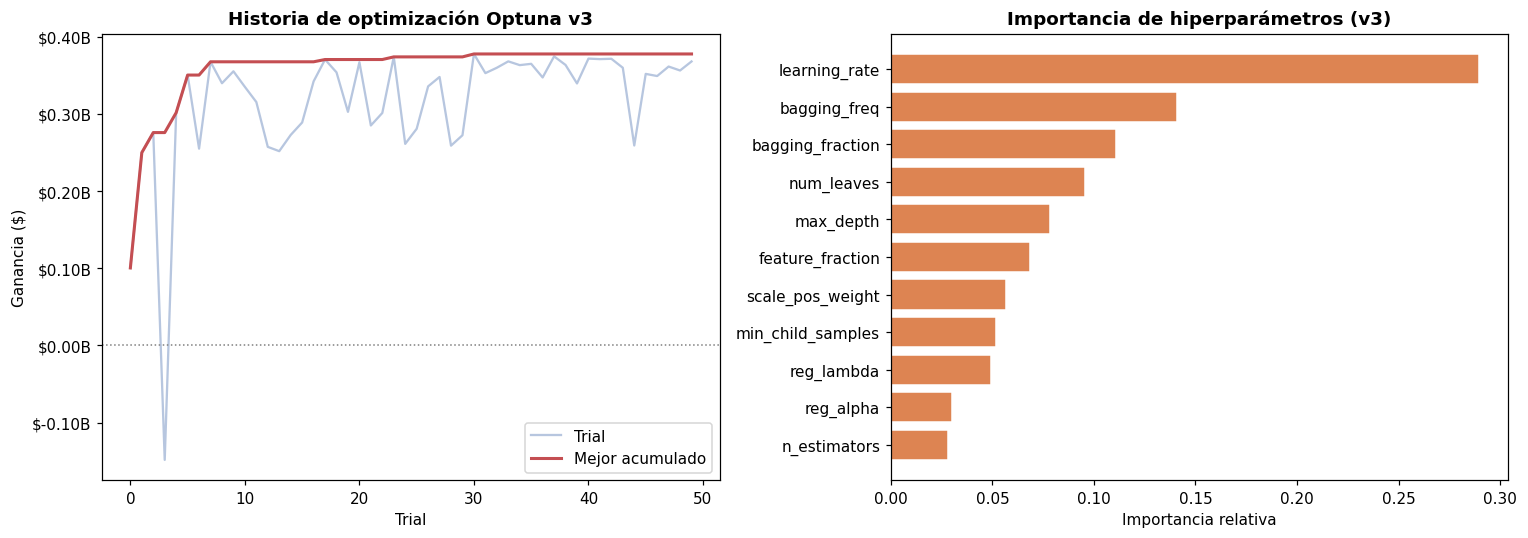

Top 10 trials:
 number       value  params_bagging_fraction  params_bagging_freq  params_feature_fraction  params_learning_rate  params_max_depth  params_min_child_samples  params_n_estimators  params_num_leaves  params_reg_alpha  params_reg_lambda  params_scale_pos_weight
     30 377685000.0                 0.427028                    4                 0.638700              0.025833                 5                       168                  950                 24          0.001483           0.548061               223.398861
     37 374550000.0                 0.438893                    4                 0.592526              0.020724                 5                       169                 1000                 42          0.008210           0.028659               198.559734
     23 373890000.0                 0.411109                    4                 0.621355              0.025089                 6                       123                  850                 19          0.

In [ ]:
# Gráficos Optuna (solo si corrió en esta sesión)
if 'study' in dir():
    valores   = [t.value for t in study.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(0, color='gray', ls=':', lw=1)
    ax.set_title('Historia de optimización Optuna v3', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Ganancia ($)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend()

    ax = axes[1]
    try:
        importances = optuna.importance.get_param_importances(study)
        pi = list(importances.keys())
        vi = list(importances.values())
        si = np.argsort(vi)
        ax.barh([pi[i] for i in si], [vi[i] for i in si], color='#DD8452', edgecolor='white')
        ax.set_title('Importancia de hiperparámetros (v3)', fontweight='bold')
        ax.set_xlabel('Importancia relativa')
    except Exception:
        ax.text(0.5, 0.5, 'Requiere más trials', ha='center', va='center', transform=ax.transAxes)
    plt.tight_layout()
    plt.show()

    # Top trials
    trials_df = study.trials_dataframe()
    print('Top 10 trials:')
    cols_m = ['number', 'value'] + [c for c in trials_df.columns if c.startswith('params_')]
    print(trials_df.nlargest(10, 'value')[cols_m].to_string(index=False))
else:
    print('(Gráficos disponibles solo si Optuna corrió en esta sesión)')

## 6 · Walk-forward completo v3


  FOLD_2 — test: 202104
AUC: 0.8520


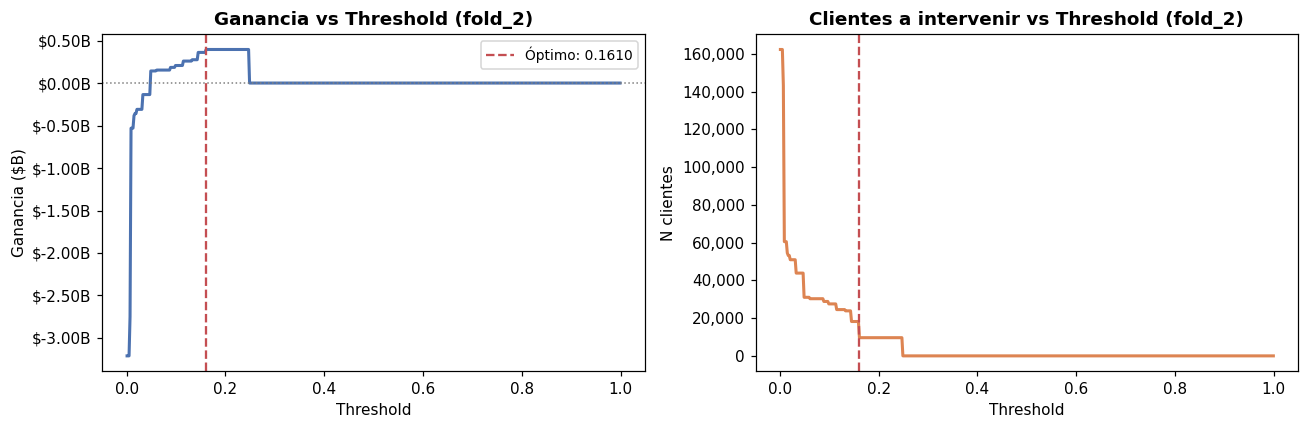

  Threshold óptimo:   0.16100
  Ganancia:           $    394,982,500
  TP detectados:      600.0
  FP (en vano):       9,037.0
  Total intervenidos: 9,637.0

  FOLD_3 — test: 202105
AUC: 0.8419


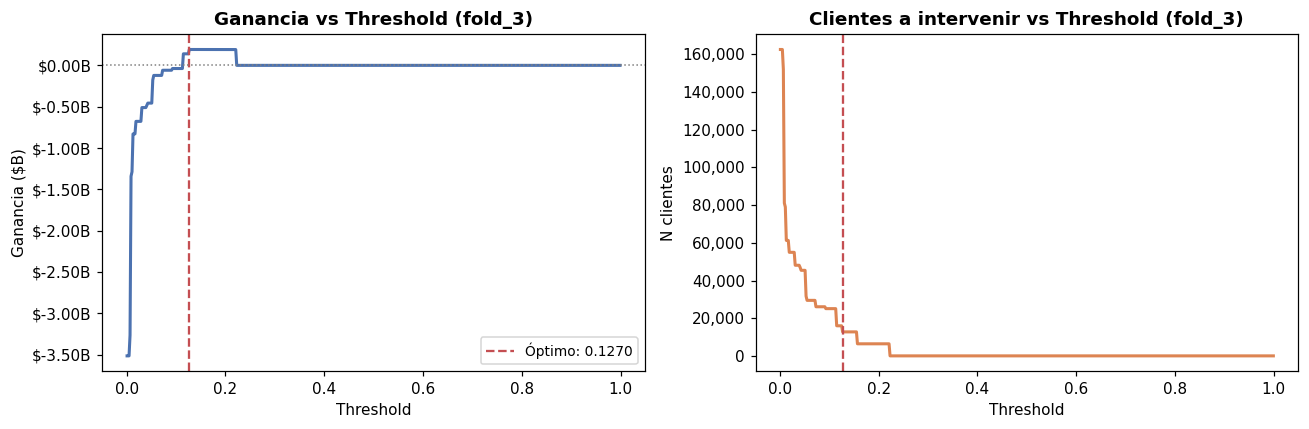

  Threshold óptimo:   0.12700
  Ganancia:           $    192,087,500
  TP detectados:      493.0
  FP (en vano):       12,242.0
  Total intervenidos: 12,735.0

  FOLD_4 — test: 202106
AUC: 0.8631


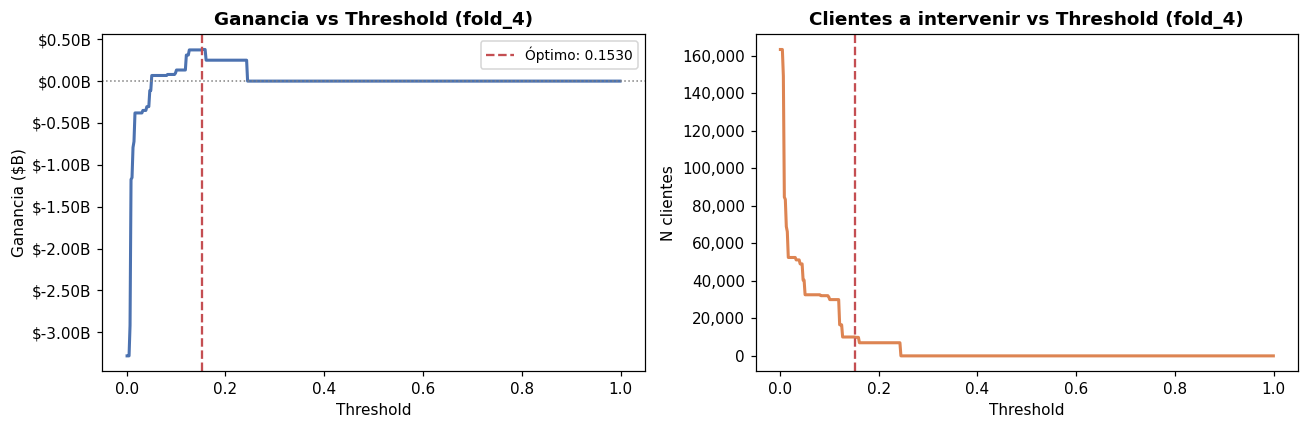

  Threshold óptimo:   0.15300
  Ganancia:           $    377,685,000
  TP detectados:      590.0
  FP (en vano):       9,276.0
  Total intervenidos: 9,866.0

RESUMEN WALK-FORWARD v3
  fold  mes_test    auc    ganancia  threshold_opt    tp      fp
fold_2    202104 0.8520 394982500.0          0.161 600.0  9037.0
fold_3    202105 0.8419 192087500.0          0.127 493.0 12242.0
fold_4    202106 0.8631 377685000.0          0.153 590.0  9276.0

--- Comparación con v2 ---
  fold_2: v3=$394,982,500 | v2=$509,795,000 | diff=$-114,812,500
  fold_3: v3=$192,087,500 | v2=$273,762,500 | diff=$-81,675,000
  fold_4: v3=$377,685,000 | v2=$420,420,000 | diff=$-42,735,000


In [ ]:
resultados_wf = []

for fold in FOLDS:
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} — test: {fold['test']}")
    print('='*55)

    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**PARAMS_OPT)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    print(f'AUC: {auc:.4f}')
    opt = plot_ganancia_threshold(yte.values, prob, f"({fold['nombre']})")

    resultados_wf.append({
        'fold': fold['nombre'], 'mes_test': fold['test'],
        'n_train': len(ytr), 'n_test': len(yte),
        'n_baja2_test': int(yte.sum()),
        'auc': round(auc, 4), 'ganancia': opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp': opt['tp'], 'fp': opt['fp'],
        'n_intervenidos': opt['n_intervenidos'],
        'version': 'v3'
    })
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

resultados_df = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD v3\n{'='*55}")
print(resultados_df[['fold','mes_test','auc','ganancia','threshold_opt','tp','fp']].to_string(index=False))

# Comparación con v2
print(f'\n--- Comparación con v2 ---')
v2 = {'fold_2': 509_795_000, 'fold_3': 273_762_500, 'fold_4': 420_420_000}
for _, row in resultados_df.iterrows():
    g_v2 = v2.get(row['fold'], 0)
    diff = row['ganancia'] - g_v2
    signo = '+' if diff >= 0 else ''
    print(f"  {row['fold']}: v3=${row['ganancia']:,.0f} | v2=${g_v2:,.0f} | diff={signo}${diff:,.0f}")

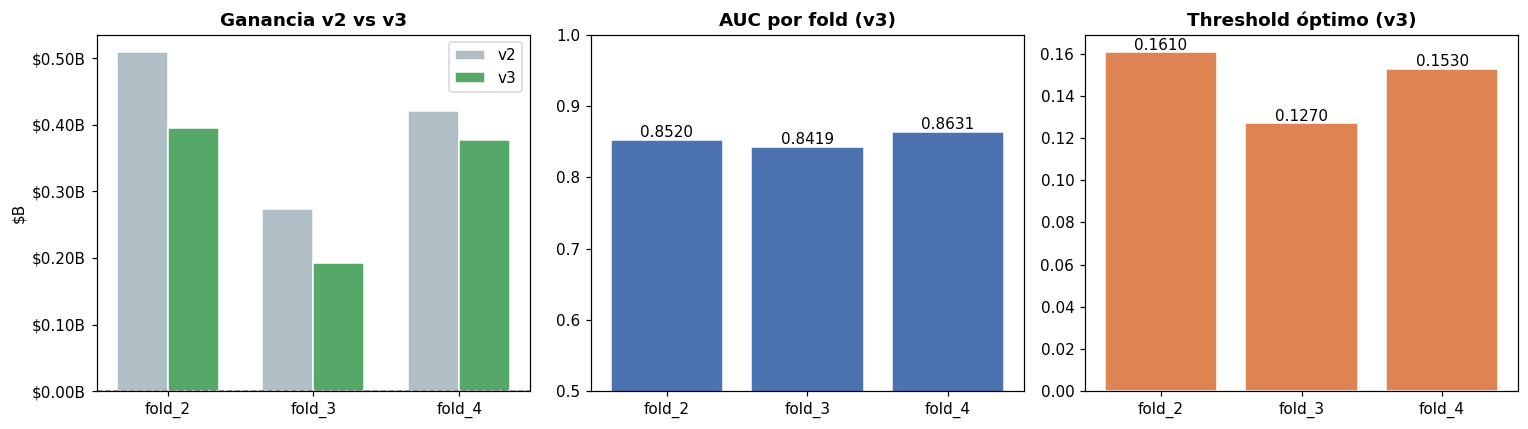

✓ Métricas guardadas: metricas_experimentos.csv


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = resultados_df['fold'].tolist()
v2_vals = [v2[f] for f in labels]

ax = axes[0]
x = np.arange(len(labels))
w = 0.35
b1 = ax.bar(x - w/2, [g/1e9 for g in v2_vals], w, label='v2', color='#B0BEC5', edgecolor='white')
b2 = ax.bar(x + w/2, resultados_df['ganancia']/1e9, w, label='v3',
            color=['#55A868' if g > 0 else '#C44E52' for g in resultados_df['ganancia']],
            edgecolor='white')
ax.set_title('Ganancia v2 vs v3', fontweight='bold')
ax.set_ylabel('$B')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.axhline(0, color='gray', ls='--', lw=1)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
ax.legend()

ax = axes[1]
ax.bar(labels, resultados_df['auc'], color='#4C72B0', edgecolor='white')
ax.set_title('AUC por fold (v3)', fontweight='bold')
ax.set_ylim(0.5, 1.0)
for i, v in enumerate(resultados_df['auc']):
    ax.text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=10)

ax = axes[2]
ax.bar(labels, resultados_df['threshold_opt'], color='#DD8452', edgecolor='white')
ax.set_title('Threshold óptimo (v3)', fontweight='bold')
for i, v in enumerate(resultados_df['threshold_opt']):
    ax.text(i, v + 0.001, f'{v:.4f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

resultados_df['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    resultados_df = pd.concat([hist, resultados_df], ignore_index=True)
resultados_df.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas: {ARCHIVO_METRICAS.name}')

## 7 · Análisis de errores (fold_4) — ¿mejoramos los FN?

In [ ]:
Xtr_f4, ytr_f4, Xte_f4, yte_f4 = get_split([202103, 202104, 202105], 202106)
modelo_f4 = lgb.LGBMClassifier(**PARAMS_OPT)
modelo_f4.fit(Xtr_f4, ytr_f4,
              eval_set=[(Xte_f4, yte_f4)],
              callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
prob_f4 = modelo_f4.predict_proba(Xte_f4)[:, 1]
opt_f4  = threshold_optimo(yte_f4.values, prob_f4)
pred_f4 = (prob_f4 >= opt_f4['threshold']).astype(int)

idx_test = df[(df[COL_PERIODO] == 202106) & df[TARGET].notna()].index
df_err = df.loc[idx_test, [COL_ID, 'cliente_edad', 'cliente_antiguedad',
                             'mrentabilidad', 'cproductos', 'mcuentas_saldo',
                             'chomebanking_transacciones', 'mcomisiones']].copy()
df_err['prob'] = prob_f4
df_err['pred'] = pred_f4
df_err['real'] = yte_f4.values
df_err['tipo'] = 'TN'
df_err.loc[(df_err.real==1) & (df_err.pred==1), 'tipo'] = 'TP'
df_err.loc[(df_err.real==0) & (df_err.pred==1), 'tipo'] = 'FP'
df_err.loc[(df_err.real==1) & (df_err.pred==0), 'tipo'] = 'FN'

print('Matriz de confusión (fold_4 v3):')
print(df_err['tipo'].value_counts())
print(f"Ganancia: ${opt_f4['ganancia']:,.0f}")
print(f"\nComparación con v2:")
print(f"  v2: $420,420,000 | FN=313 | TP=785")
print(f"  v3: ${opt_f4['ganancia']:,.0f} | FN={df_err[df_err.tipo=='FN'].shape[0]} | TP={df_err[df_err.tipo=='TP'].shape[0]}")

del Xtr_f4, ytr_f4; gc.collect()

Matriz de confusión (fold_4 v3):
tipo
TN    152866
FP      9276
TP       590
FN       508
Name: count, dtype: int64
Ganancia: $377,685,000

Comparación con v2:
  v2: $420,420,000 | FN=313 | TP=785
  v3: $377,685,000 | FN=508 | TP=590


7288

Perfil TP vs FN (v3):
                    TP_media  FN_media  dif_%
cliente_edad           46.73     47.51    1.7
cliente_antiguedad    107.54    115.92    7.8
mrentabilidad        2277.96   1806.17  -20.7
cproductos              5.92      6.96   17.6
mcuentas_saldo     -18172.05  77449.91  526.2
mcomisiones          1345.70   1572.63   16.9
prob                    0.22      0.08  -63.3


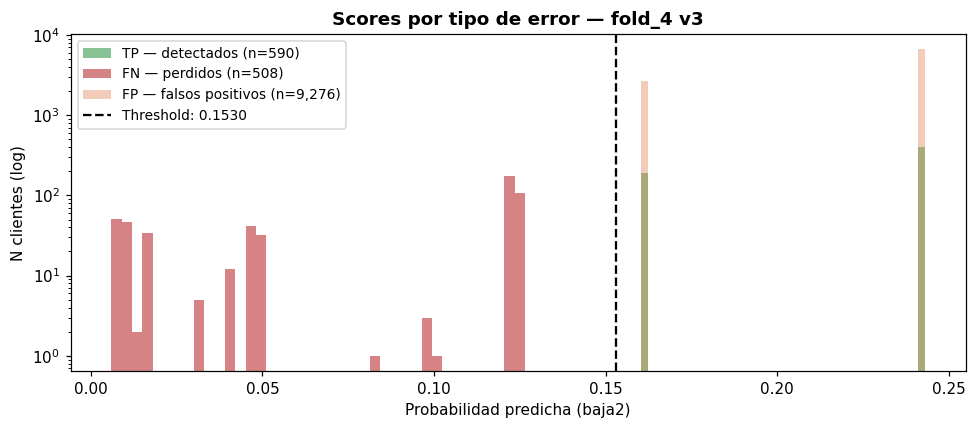

4012

In [ ]:
# Perfil TP vs FN — comparamos con v2
vars_perfil = ['cliente_edad', 'cliente_antiguedad', 'mrentabilidad',
               'cproductos', 'mcuentas_saldo', 'mcomisiones', 'prob']
vars_perfil = [v for v in vars_perfil if v in df_err.columns]

churners = df_err[df_err['real'] == 1]
perfil = pd.concat([
    churners[churners['tipo']=='TP'][vars_perfil].mean().rename('TP_media'),
    churners[churners['tipo']=='FN'][vars_perfil].mean().rename('FN_media'),
], axis=1)
perfil['dif_%'] = ((perfil['FN_media'] - perfil['TP_media']) / perfil['TP_media'].abs() * 100).round(1)

print('Perfil TP vs FN (v3):')
print(perfil.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for tipo, color, alpha, label in [
    ('TP', '#55A868', 0.7, 'TP — detectados'),
    ('FN', '#C44E52', 0.7, 'FN — perdidos'),
    ('FP', '#DD8452', 0.4, 'FP — falsos positivos'),
]:
    sub = df_err[df_err['tipo'] == tipo]['prob']
    if len(sub): ax.hist(sub, bins=40, alpha=alpha, color=color, label=f'{label} (n={len(sub):,})')
ax.axvline(opt_f4['threshold'], color='black', ls='--', lw=1.5,
           label=f"Threshold: {opt_f4['threshold']:.4f}")
ax.set_yscale('log')
ax.set_title('Scores por tipo de error — fold_4 v3', fontweight='bold')
ax.set_xlabel('Probabilidad predicha (baja2)')
ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

del df_err, churners, Xte_f4, yte_f4; gc.collect()

## 8 · Predicción final sobre 202108

In [ ]:
# Usamos threshold del fold_4 (el más representativo del escenario real)
# Si los thresholds son consistentes entre folds, el promedio también es válido
thresholds_folds = resultados_df['threshold_opt'].values[-3:]
threshold_fold4  = float(thresholds_folds[-1])
threshold_prom   = float(np.mean(thresholds_folds))

print(f'Thresholds por fold: {thresholds_folds}')
print(f'Threshold fold_4:    {threshold_fold4:.5f}')
print(f'Threshold promedio:  {threshold_prom:.5f}')
print(f'\n→ Usando threshold fold_4 ({threshold_fold4:.5f}) — más cercano al escenario real')

THRESHOLD_FINAL = threshold_fold4

mask_tf = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
X_tf = df.loc[mask_tf, FEATURE_COLS]
y_tf = df.loc[mask_tf, TARGET].astype(int)

mask_pred = df[COL_PERIODO] == MES_PREDECIR
X_pred   = df.loc[mask_pred, FEATURE_COLS]
ids_pred = df.loc[mask_pred, COL_ID]

print(f'\nTrain final: {len(y_tf):,} filas (baja2={y_tf.sum():,})')
print(f'A predecir:  {len(X_pred):,} clientes (202108)')

modelo_final = lgb.LGBMClassifier(**PARAMS_OPT)
modelo_final.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])

prob_final = modelo_final.predict_proba(X_pred)[:, 1]
pred_final = (prob_final >= THRESHOLD_FINAL).astype(int)

del X_tf, y_tf; gc.collect()
print(f'\nClientes a intervenir: {pred_final.sum():,} ({pred_final.mean()*100:.2f}%)')

Thresholds por fold: [0.161 0.127 0.153]
Threshold fold_4:    0.15300
Threshold promedio:  0.14700

→ Usando threshold fold_4 (0.15300) — más cercano al escenario real

Train final: 650,066 filas (baja2=4,067)
A predecir:  164,647 clientes (202108)

Clientes a intervenir: 36,671 (22.27%)


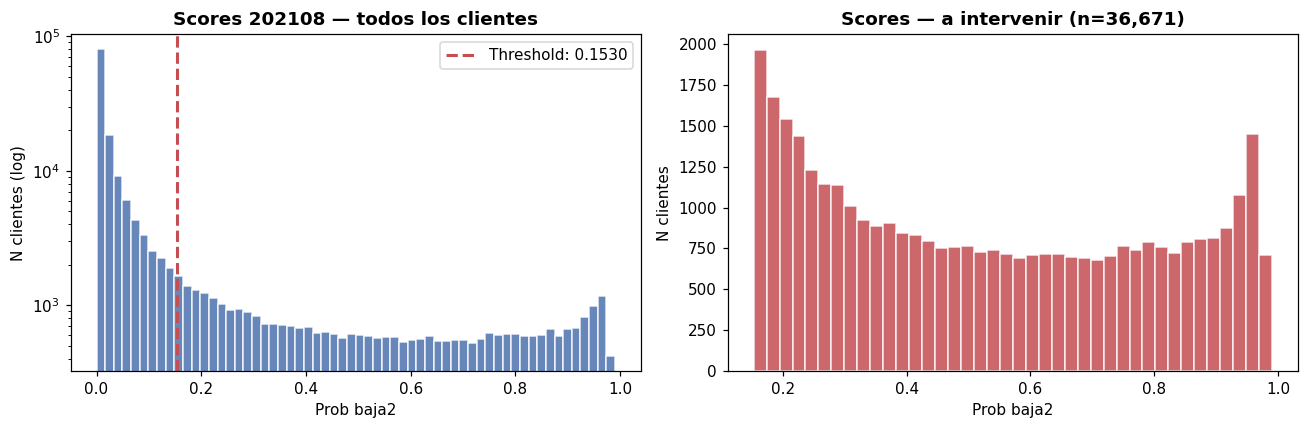

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.hist(prob_final, bins=60, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.axvline(THRESHOLD_FINAL, color='#C44E52', ls='--', lw=2,
           label=f'Threshold: {THRESHOLD_FINAL:.4f}')
ax.set_yscale('log')
ax.set_title('Scores 202108 — todos los clientes', fontweight='bold')
ax.set_xlabel('Prob baja2')
ax.set_ylabel('N clientes (log)')
ax.legend()

ax = axes[1]
pred1 = prob_final[pred_final == 1]
ax.hist(pred1, bins=40, color='#C44E52', edgecolor='white', alpha=0.85)
ax.set_title(f'Scores — a intervenir (n={len(pred1):,})', fontweight='bold')
ax.set_xlabel('Prob baja2')
ax.set_ylabel('N clientes')
plt.tight_layout()
plt.show()

In [ ]:
submission = pd.DataFrame({
    COL_ID:       ids_pred.values,
    'Predicted':  pred_final,
    'prob_baja2': prob_final.round(6),
})
submission.to_csv(ARCHIVO_SUBMISSION, index=False)
print(f'✓ Submission: {ARCHIVO_SUBMISSION.name}')
print(f'  Pred=1: {submission["Predicted"].sum():,} | Pred=0: {(submission["Predicted"]==0).sum():,}')
print(submission.head())

✓ Submission: submission_v3_20261004_1611.csv
  Pred=1: 36,671 | Pred=0: 127,976
   numero_de_cliente  Predicted  prob_baja2
0           12159854          0    0.058925
1           12159858          0    0.029543
2           12160484          0    0.139001
3           12160591          0    0.010033
4           12160747          0    0.108847


In [ ]:
print('=' * 65)
print('RESUMEN FINAL v3')
print('=' * 65)
print(f'FE: {len(FEATURE_COLS)} features (v2 tenía 241)')
print(f'Nuevas familias: lag2, aceleración, media/std/cv ventana 3, combinaciones')
print(f'Optuna fix: num_leaves desacoplado de max_depth')
print()
print('Walk-forward v3:')
for _, row in resultados_df.drop_duplicates('fold').iterrows():
    if row.get('version') != 'v3': continue
    g_v2 = v2.get(row['fold'], 0)
    diff = row['ganancia'] - g_v2
    signo = '+' if diff >= 0 else ''
    print(f"  {row['fold']}: ${row['ganancia']:>15,.0f} (vs v2: {signo}${diff:,.0f}) | AUC={row['auc']:.4f}")
print()
print(f'Threshold final: {THRESHOLD_FINAL:.5f} (fold_4)')
print(f'Clientes a intervenir: {pred_final.sum():,}')
print(f'Archivos: {ARCHIVO_SUBMISSION.name}')

del df; gc.collect()
print('\n✓ Notebook v3 completada.')

RESUMEN FINAL v3
FE: 323 features (v2 tenía 241)
Nuevas familias: lag2, aceleración, media/std/cv ventana 3, combinaciones
Optuna fix: num_leaves desacoplado de max_depth

Walk-forward v3:

Threshold final: 0.15300 (fold_4)
Clientes a intervenir: 36,671
Archivos: submission_v3_20261004_1611.csv

✓ Notebook v3 completada.
